<a href="https://colab.research.google.com/github/JAVEED96-alt/Diabetes_Prediction_ML/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
data = pd.read_csv('ted_main_v2.csv')

In [41]:
df = pd.DataFrame(data)

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   speaker_name   2160 non-null   object
 1   title          2160 non-null   object
 2   posted_date    2160 non-null   object
 3   duration       2160 non-null   object
 4   Link           2160 non-null   object
 5   about_speaker  1744 non-null   object
 6   about_talk     2159 non-null   object
 7   views          2155 non-null   object
 8   tags           2153 non-null   object
dtypes: object(9)
memory usage: 152.0+ KB


pre processing the data and preforming the EDA:Expolraty Data Analysis

In [43]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   speaker_name   2160 non-null   object
 1   title          2160 non-null   object
 2   posted_date    2160 non-null   object
 3   duration       2160 non-null   object
 4   Link           2160 non-null   object
 5   about_speaker  1744 non-null   object
 6   about_talk     2159 non-null   object
 7   views          2155 non-null   object
 8   tags           2153 non-null   object
dtypes: object(9)
memory usage: 152.0+ KB
None


In [44]:
df.head()

,speaker_name,title,posted_date,duration,Link,about_speaker,about_talk,views,tags
0,Alex Gendler,The Egyptian myth of the death of Osiris,Jul 2020,3:56,https://www.ted.com/talks/alex_gendler_the_egy...,NaN,"Long jealous of his older brother Osiris, the ...","208,703","education,ancient world,TED-Ed"
1,Shari Davis,What if you could help decide how the governme...,Jul 2020,10:28,https://www.ted.com/talks/shari_davis_what_if_...,As a leader of the Participatory Budgeting Pro...,What if you could help decide how the governme...,"425,688","democracy,leadership,community"
2,Nita Mosby Tyler,Want a more just world? Be an unlikely ally,Jul 2020,10:15,https://www.ted.com/talks/nita_mosby_tyler_wan...,Nita Mosby Tyler specializes in the developmen...,A more equal world starts with you. Citing a f...,"460,269","activism,inequality,race"
3,Susan Lupack,The race to decode a mysterious language,Jul 2020,4:24,https://www.ted.com/talks/susan_lupack_the_rac...,NaN,"In the early 1900s, archaeologist Sir Arthur E...","350,202","TED-Ed,education,language"
4,Ariel Waldman,The colorful critter world of microbes in Anta...,Jul 2020,5:56,https://www.ted.com/talks/ariel_waldman_the_co...,"An artist who's pivoted to science, Ariel Wald...","In this tour of the microscopic world, explore...","333,482","science,animals,exploration"


In [45]:
df.tail()

,speaker_name,title,posted_date,duration,Link,about_speaker,about_talk,views,tags
2155,Nancy Frates,Meet the mom who started the Ice Bucket Challenge,Nov 2014,18:53,https://www.ted.com/talks/nancy_frates_meet_th...,Nancy Frates and her family have raised a proj...,Remember the Ice Bucket Challenge craze this s...,"1,081,901",NaN
2156,Will Marshall,Tiny satellites show us the Earth as it change...,Nov 2014,8:01,https://www.ted.com/talks/will_marshall_tiny_s...,"At Planet, Will Marshall leads overall strateg...",Satellite imaging has revolutionized our knowl...,"1,914,256",NaN
2157,David Grady,How to save the world (or at least yourself) f...,Nov 2014,6:34,https://www.ted.com/talks/david_grady_how_to_s...,David Grady is on a crusade to help you take b...,"An epidemic of bad, inefficient, overcrowded m...","2,504,886",NaN
2158,Vincent Moon and Naná Vasconcelos,Hidden music rituals around the world,Nov 2014,24:13,https://www.ted.com/talks/vincent_moon_and_nan...,"A jazz icon since the late 1960s, Naná Vasconc...",Vincent Moon travels the world with a backpack...,"1,104,616",NaN
2159,Alex Gendler,Why elephants never forget,Nov 2014,5:22,https://www.ted.com/talks/alex_gendler_why_ele...,NaN,It's a common saying that elephants never forg...,"4,097,024",NaN


In [46]:
df.isnull().sum()

,0
speaker_name,0
title,0
posted_date,0
duration,0
Link,0
about_speaker,416
about_talk,1
views,5
tags,7


In [47]:
df.shape

(2160, 9)

In [48]:
df.isnull().sum()

,0
speaker_name,0
title,0
posted_date,0
duration,0
Link,0
about_speaker,416
about_talk,1
views,5
tags,7


In [49]:
df.duplicated().sum()

np.int64(0)

In [50]:
df.describe()

,speaker_name,title,posted_date,duration,Link,about_speaker,about_talk,views,tags
count,2160,2160,2160,2160,2160,1744,2159,2155,2153
unique,1915,2160,69,890,2160,1629,2159,2155,2066
top,Alex Gendler,How Christmas lights helped guerrillas put dow...,Sep 2018,4:49,https://www.ted.com/talks/jose_miguel_sokoloff...,Alex Rosenthal takes everyday experiences and ...,It's a common saying that elephants never forg...,"4,097,024","TED-Ed,animation,education"
freq,31,1,59,11,1,12,1,1,15


In [51]:
df["views"] = pd.to_numeric(
    df["views"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

df["views"].describe()

,views
count,2.155000e+03
mean,2.060034e+06
std,2.944472e+06
min,1.023100e+04
25%,9.884700e+05
50%,1.496189e+06
75%,2.128472e+06
max,6.023746e+07


In [52]:
df.dtypes

,0
speaker_name,object
title,object
posted_date,object
duration,object
Link,object
about_speaker,object
about_talk,object
views,float64
tags,object


In [53]:
df["views"]

,views
0,208703.0
1,425688.0
2,460269.0
3,350202.0
4,333482.0
...,...
2155,1081901.0
2156,1914256.0
2157,2504886.0
2158,1104616.0


In [56]:
print(df.columns.tolist)

<bound method IndexOpsMixin.tolist of Index(['speaker_name', 'title', 'posted_date', 'duration', 'Link',
       'about_speaker', 'about_talk', 'views', 'tags'],
      dtype='object')>


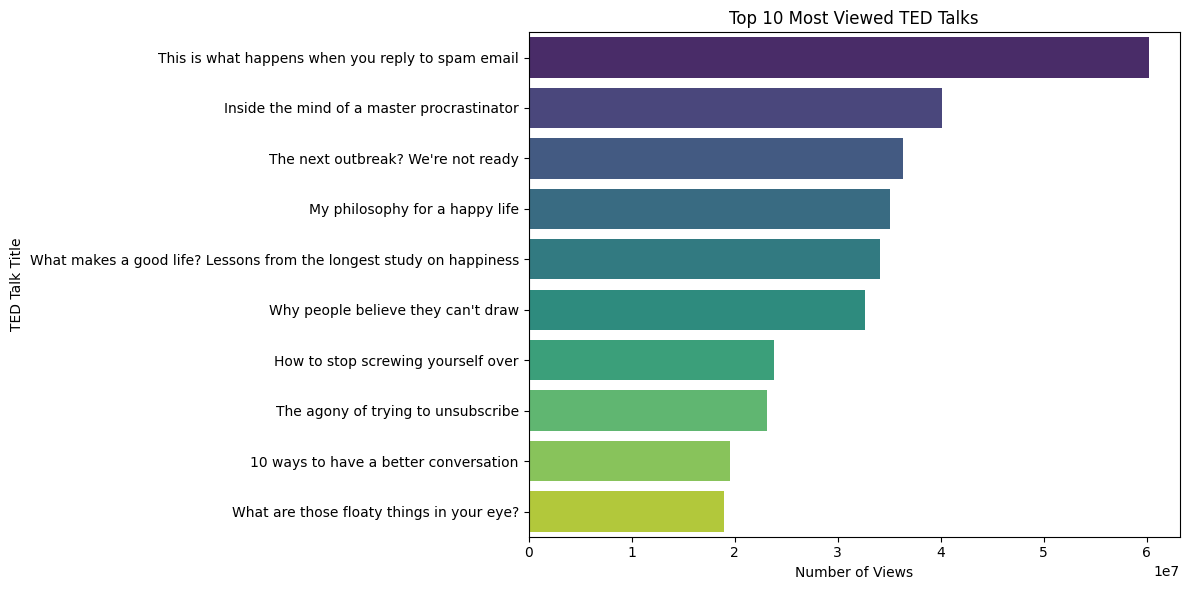

In [57]:
top_10 = df.nlargest(10, "views")

# Plot
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="views",
    y="title",
    hue="title",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Most Viewed TED Talks")
plt.xlabel("Number of Views")
plt.ylabel("TED Talk Title")
plt.tight_layout()

In [58]:
print(df["duration"].head(10))
print(df["duration"].dtype)

0     3:56
1    10:28
2    10:15
3     4:24
4     5:56
5    14:51
6     5:10
7    10:58
8    26:32
9     4:54
Name: duration, dtype: object
object


In [59]:
df["duration"]

,duration
0,3:56
1,10:28
2,10:15
3,4:24
4,5:56
...,...
2155,18:53
2156,8:01
2157,6:34
2158,24:13


In [60]:
parts = df["duration"].str.split(":",expand=True)

In [61]:
minuts = pd.to_numeric(parts[0],errors="coerce")
secound = pd.to_numeric(parts[1],errors="coerce")

df['duration_seconds'] = minuts*60 + secound

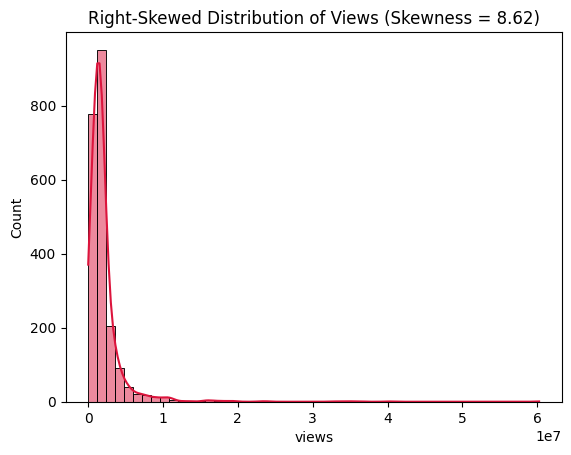

In [89]:
sns.histplot(data=df, x='views', kde=True, color='crimson', bins=50)
plt.title('Right-Skewed Distribution of Views (Skewness = 8.62)')
plt.show()

In [62]:
print(df["duration_seconds"])



0        236.0
1        628.0
2        615.0
3        264.0
4        356.0
         ...  
2155    1133.0
2156     481.0
2157     394.0
2158    1453.0
2159     322.0
Name: duration_seconds, Length: 2160, dtype: float64


In [63]:
df["duration_seconds"].describe()

,duration_seconds
count,2155.000000
mean,659.196752
std,340.526498
min,60.000000
25%,343.500000
50%,682.000000
75%,863.500000
max,3503.000000


Text(0.5, 1.0, 'Box Plot of views(Checking yh)')

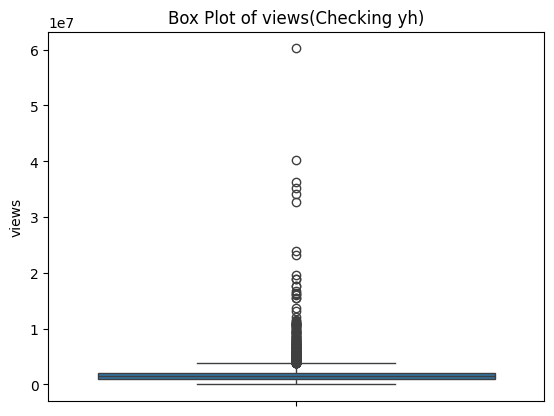

In [64]:
sns.boxplot(y=df["views"])
plt.title("Box Plot of views(Checking yh)")

In [65]:
df = df.dropna(subset=['views'])

In [66]:
df['posted_date'] = pd.to_datetime(df['posted_date'], format='%b %Y')

# Extract useful temporal features
df['year'] = df['posted_date'].dt.year
df['month'] = df['posted_date'].dt.month

In [67]:
# Convert tags string into a list of tags (handling NaNs safely)
df['tags_list'] = df['tags'].fillna('').str.split(',')

In [68]:
df['month']

,month
0,7
1,7
2,7
3,7
4,7
...,...
2155,11
2156,11
2157,11
2158,11


In [69]:
df['tags']

,tags
0,"education,ancient world,TED-Ed"
1,"democracy,leadership,community"
2,"activism,inequality,race"
3,"TED-Ed,education,language"
4,"science,animals,exploration"
...,...
2155,NaN
2156,NaN
2157,NaN
2158,NaN


In [70]:
df['tags_list']

,tags_list
0,"[education, ancient world, TED-Ed]"
1,"[democracy, leadership, community]"
2,"[activism, inequality, race]"
3,"[TED-Ed, education, language]"
4,"[science, animals, exploration]"
...,...
2155,[]
2156,[]
2157,[]
2158,[]


In [71]:
from scipy import stats

# Drop NaN values for the test
views_clean = df['views'].dropna()

# D'Agostino's K-squared test (good for large samples)
stat, p_value = stats.normaltest(views_clean)
print(f'Statistics=%.3f, p=%.3f' % (stat, p_value))
if p_value > 0.05:
  print('Sample looks Gaussian (normal)')
else:
  print('Sample does not look Gaussian (not normal)')

Statistics=3155.998, p=0.000
Sample does not look Gaussian (not normal)


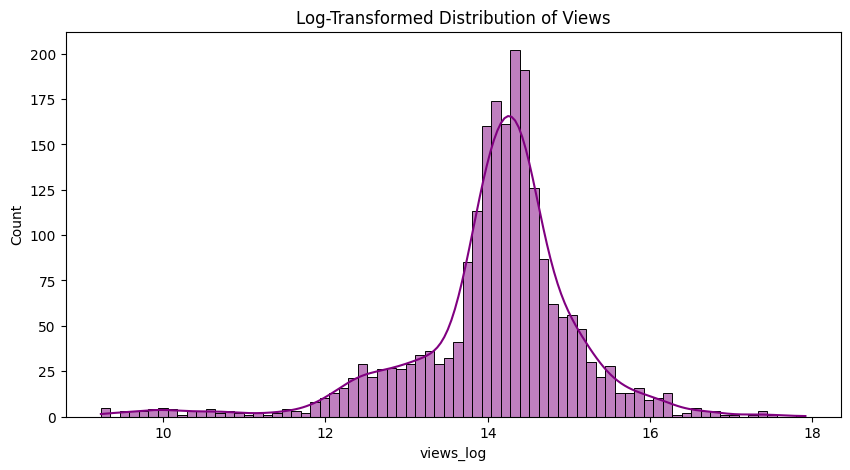

In [72]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Apply log transformation to normalize view counts
df['views_log'] = np.log1p(df['views'])

# Check the new distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='views_log', kde=True, color='purple')
plt.title('Log-Transformed Distribution of Views')
plt.show()

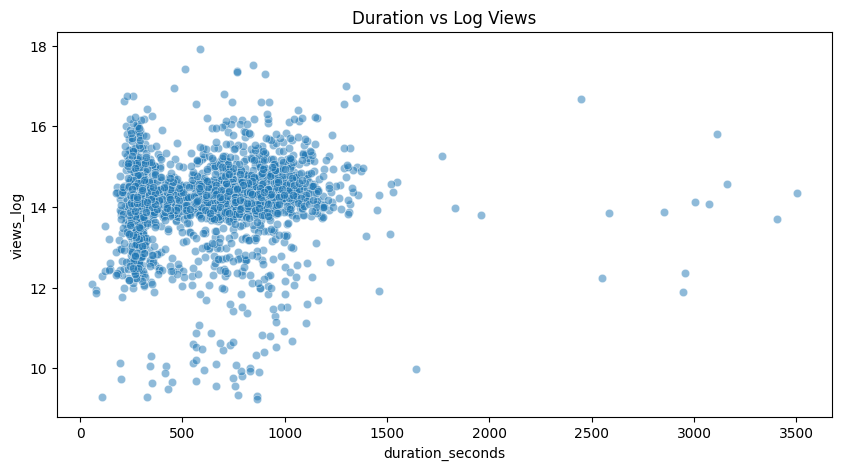

In [73]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='duration_seconds', y='views_log', alpha=0.5)
plt.title('Duration vs Log Views')
plt.show()

In [80]:
# Explode the list of tags into individual rows and find the top 10 tags
df['top_tags'] = df.explode('tags_list')['tags_list'].str.strip().value_counts().head(10)
print(top_tags)

tags_list
TED-Ed           331
animation        207
communication    152
education        151
activism         147
science          144
health           126
history          119
art              116
community        112
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

/tmp/ipykernel_4068/3228519428.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_filtered, x='tags_list', y='month', palette='Set2')


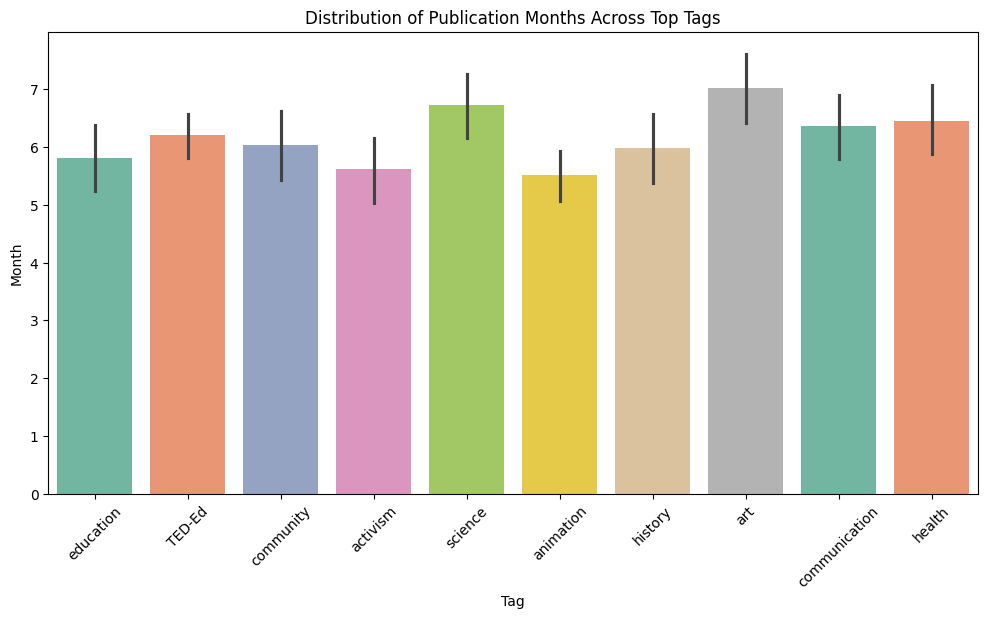

In [86]:
# Get the list of top 10 tags
top_tags_list = df.explode('tags_list')['tags_list'].str.strip().value_counts().head(10).index.tolist()

# Filter df for rows containing any of the top tags and explode
df_exploded = df.explode('tags_list')
df_exploded['tags_list'] = df_exploded['tags_list'].str.strip()
df_filtered = df_exploded[df_exploded['tags_list'].isin(top_tags_list)]

# Plot using the correct column names ('tags_list' and 'month')
plt.figure(figsize=(12, 6))
sns.barplot(data=df_filtered, x='tags_list', y='month', palette='Set2')
plt.title('Distribution of Publication Months Across Top Tags')
plt.xlabel('Tag')
plt.ylabel('Month')
plt.xticks(rotation=45)
plt.show()